# 07 · Experimentos de clustering registrados en MLflow (issue #15 · ML-03)

**Objetivo:** pasar de "funciona" a "es el mejor de los que he probado, y puedo demostrarlo". Cada prueba queda registrada en MLflow con sus parámetros y métricas, para compararlas.

**Qué se compara (primera tanda, 4 variables acordadas):**
- Matriz **con PCA** (≥ 85 % de varianza) frente a **sin PCA** (4 variables escaladas).
- K-Means con K de 2 a 10.
- Estabilidad de K=5 con 5 semillas.
- DBSCAN como complemento para atípicos.

Las matrices las genera el **generador de Elena** (`data/processed/generadorMatrices/`), no se calculan a mano en el notebook. Para probar otra lista de variables basta con otro archivo de configuración.

**Límite conocido:** el generador ajusta el preprocesado sobre los 8.132 municipios completos (exploratorio). Para validar con particiones habría que separar ajuste y transformación (ver `LEEME.md` del generador).

In [4]:
import json, subprocess, sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

SEMILLA = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'notebooks').is_dir())
DATASET = ROOT / 'data/processed/sitewise_v03/dataset_municipal.csv'
GENERADOR = ROOT / 'data/processed/generadorMatrices'
SALIDA = ROOT / 'data/processed/sitewise_ml'
MATRICES = SALIDA / 'mlflow_matrices'
assert DATASET.exists(), 'Genera antes el dataset con los notebooks 01, 02 y 03'
assert (GENERADOR / 'generar_matriz.py').exists(), 'Falta el generador de matrices (PR #39 de Elena)'

# MLflow 3 ya no admite la carpeta ./mlruns como almacén: usamos una base SQLite dentro de mlruns/ (ignorada por Git).
MLRUNS = Path(os.environ.get('SITEWISE_MLRUNS', ROOT / 'mlruns'))
MLRUNS.mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri('sqlite:///' + (MLRUNS / 'mlflow.db').as_posix())
NOMBRE_EXPERIMENTO = 'sitewise-clustering-4-variables'
if mlflow.get_experiment_by_name(NOMBRE_EXPERIMENTO) is None:
    mlflow.create_experiment(NOMBRE_EXPERIMENTO, artifact_location=(MLRUNS / 'artifacts').as_uri())
mlflow.set_experiment(NOMBRE_EXPERIMENTO)
pd.set_option('display.width', 200)
print('MLflow', mlflow.__version__, '| registros en la carpeta mlruns/')

d:\HELEN\PERSONAL\FORMACIÓN\0-ia_formacion\BOOTCAMP - F5\CURSO\PROYECTO_FINAL\SiteWise\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/18 12:15:40 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/18 12:15:40 INFO mlflow.store.db.utils: Updating database tables


MLflow 3.18.0 | registros en la carpeta mlruns/


## 1. Generar las dos matrices con el generador de Elena

Se parte de su configuración de 4 variables. La segunda variante es la misma con `"pca": null`. El generador no sobrescribe: si la carpeta ya existe, se reutiliza.

In [5]:
base = json.loads((GENERADOR / 'config_4_variables.json').read_text(encoding='utf-8-sig'))
CONFIGS = {
    'con_pca': base,
    'sin_pca': {**base, 'pca': None},
}
MATRICES.mkdir(parents=True, exist_ok=True)

def generar(nombre, config):
    carpeta = MATRICES / nombre
    if not carpeta.exists():
        ruta_config = MATRICES / f'config_{nombre}.json'
        ruta_config.write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
        res = subprocess.run([sys.executable, str(GENERADOR / 'generar_matriz.py'), '--dataset', str(DATASET),
                              '--config', str(ruta_config), '--salida', str(carpeta)], capture_output=True, text=True)
        assert res.returncode == 0, res.stderr
        print(f'Matriz {nombre} generada en', carpeta.relative_to(ROOT))
    return carpeta

carpetas = {n: generar(n, c) for n, c in CONFIGS.items()}
informes = {n: json.loads((c / 'informe.json').read_text(encoding='utf-8')) for n, c in carpetas.items()}
for n, i in informes.items():
    print(n, '| filas:', i['filas_matriz'], '| imputados:', i['valores_imputados'], '| varianza PCA:',
          round(i['pca']['varianza_acumulada'], 4) if i['pca'] else None)

Matriz con_pca generada en data\processed\sitewise_ml\mlflow_matrices\con_pca
Matriz sin_pca generada en data\processed\sitewise_ml\mlflow_matrices\sin_pca
con_pca | filas: 8132 | imputados: {'poblacion_2025': 0, 'suelo_industrial_cartografiado_pct': 0, 'dist_recta_eje_autovia_km': 56, 'dist_recta_ttm_km': 161} | varianza PCA: 0.8917
sin_pca | filas: 8132 | imputados: {'poblacion_2025': 0, 'suelo_industrial_cartografiado_pct': 0, 'dist_recta_eje_autovia_km': 56, 'dist_recta_ttm_km': 161} | varianza PCA: None


## 2. Cargar las matrices

Se carga `cod_ine` como texto y se excluye del cálculo. Con PCA se usa `matriz_pca.csv`; sin PCA, `matriz_ml.csv` (ya escalada). No se vuelve a escalar.

In [6]:
def cargar(nombre, archivo):
    t = pd.read_csv(carpetas[nombre] / archivo, dtype={'cod_ine': str})
    return t['cod_ine'].copy(), t.drop(columns='cod_ine')

codigos, X_pca = cargar('con_pca', 'matriz_pca.csv')
codigos2, X_sin = cargar('sin_pca', 'matriz_ml.csv')
assert (codigos == codigos2).all() and codigos.is_unique
MATRIZ = {'con_pca': X_pca, 'sin_pca': X_sin}
print({n: m.shape for n, m in MATRIZ.items()})

{'con_pca': (8132, 3), 'sin_pca': (8132, 4)}


## 3. K-Means con K de 2 a 10 (una ejecución de MLflow por prueba)

Se registran los parámetros (configuración, variables, PCA, K, semilla, huella del dataset) y las métricas: inercia, Silhouette, Davies-Bouldin, Calinski-Harabasz y tamaño del grupo menor.

In [7]:
def parametros_comunes(nombre):
    i = informes[nombre]
    return {
        'configuracion': nombre,
        'variables': ', '.join(i['configuracion']['variables']),
        'usa_pca': i['pca'] is not None,
        'n_dimensiones': MATRIZ[nombre].shape[1],
        'varianza_pca': round(i['pca']['varianza_acumulada'], 4) if i['pca'] else 'no aplica',
        'filas': i['filas_matriz'],
        'sha256_dataset': i['sha256_dataset'][:12],
    }

filas = []
for nombre, X in MATRIZ.items():
    for k in range(2, 11):
        km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X)
        m = {
            'inercia': km.inertia_,
            'silhouette': silhouette_score(X, km.labels_),
            'davies_bouldin': davies_bouldin_score(X, km.labels_),
            'calinski_harabasz': calinski_harabasz_score(X, km.labels_),
            'grupo_menor_pct': np.bincount(km.labels_).min() / len(X) * 100,
        }
        with mlflow.start_run(run_name=f'kmeans_{nombre}_k{k}'):
            mlflow.set_tags({'algoritmo': 'kmeans', 'tipo': 'barrido_k'})
            mlflow.log_params({**parametros_comunes(nombre), 'k': k, 'semilla': SEMILLA, 'n_init': 20})
            mlflow.log_metrics(m)
            mlflow.log_artifact(str(MATRICES / f'config_{nombre}.json'))
        filas.append({'config': nombre, 'k': k, **m})

barrido = pd.DataFrame(filas)
tabla = barrido.pivot(index='k', columns='config', values='silhouette')
print('Silhouette por K y configuración:'); print(tabla.round(3).to_string())

2026/11/18 12:16:18 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/18 12:16:18 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

Silhouette por K y configuración:
config  con_pca  sin_pca
k                       
2         0.420    0.399
3         0.285    0.284
4         0.279    0.253
5         0.274    0.258
6         0.266    0.249
7         0.258    0.238
8         0.252    0.235
9         0.245    0.225
10        0.245    0.223


### Gráfico de métricas por K

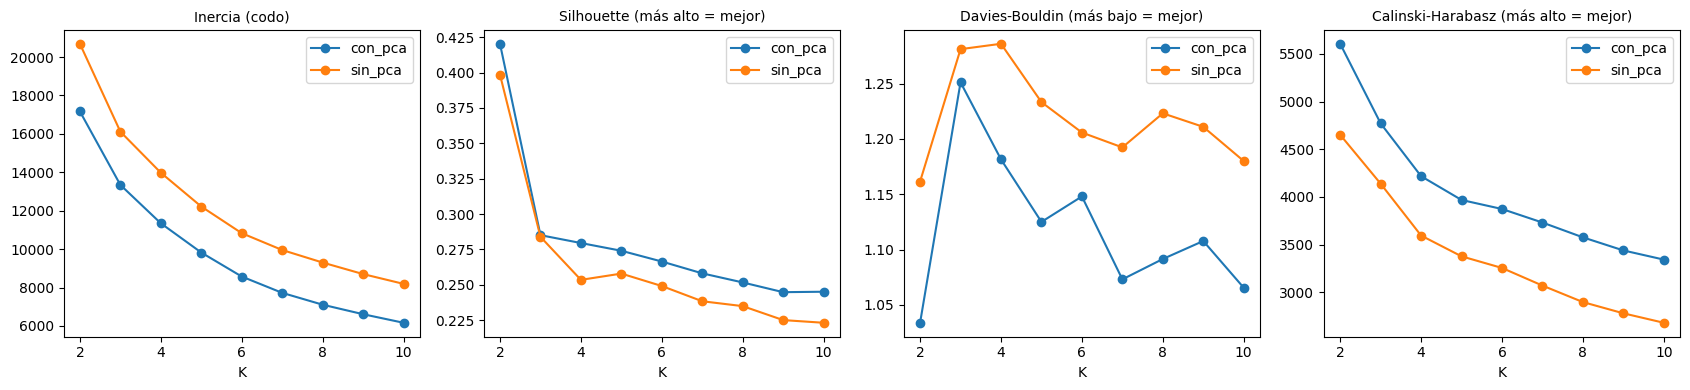

In [8]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (col, titulo) in zip(ejes, [('inercia', 'Inercia (codo)'), ('silhouette', 'Silhouette (más alto = mejor)'),
                                      ('davies_bouldin', 'Davies-Bouldin (más bajo = mejor)'),
                                      ('calinski_harabasz', 'Calinski-Harabasz (más alto = mejor)')]):
    for nombre, g in barrido.groupby('config'):
        ax.plot(g['k'], g[col], marker='o', label=nombre)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel('K'); ax.legend()
plt.tight_layout(); plt.show()

## 4. ¿Con y sin PCA dan los mismos grupos?

Las métricas de dos espacios distintos (3 componentes frente a 4 variables) **no son estrictamente comparables entre sí**, así que se compara también si los grupos coinciden (ARI: 1 = idénticos) y si reproducen los del notebook 05.

In [9]:
K_ELEGIDO = 5
previo = pd.read_csv(SALIDA / 'clusters_kmeans_v01.csv', dtype={'cod_ine': str}).set_index('cod_ine')['grupo_kmeans'].reindex(codigos).to_numpy()

filas_ari = []
etq = {}
for k in range(2, 11):
    a = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit_predict(X_pca)
    b = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit_predict(X_sin)
    etq[k] = {'con_pca': a, 'sin_pca': b}
    filas_ari.append({'k': k, 'ari_con_pca_vs_sin_pca': adjusted_rand_score(a, b)})
ari_k = pd.DataFrame(filas_ari).set_index('k')
print('ARI entre los grupos con PCA y sin PCA, por K (1 = idénticos):')
print(ari_k.round(3).to_string())

ari_vs_nb05 = {n: adjusted_rand_score(previo, e) for n, e in etq[K_ELEGIDO].items()}
with mlflow.start_run(run_name='comparacion_pca_vs_sin_pca'):
    mlflow.set_tags({'algoritmo': 'kmeans', 'tipo': 'comparacion'})
    mlflow.log_params({'k_elegido': K_ELEGIDO, 'semilla': SEMILLA})
    mlflow.log_metrics({f'ari_pca_vs_sin_pca_k{k}': v for k, v in ari_k['ari_con_pca_vs_sin_pca'].items()})
    mlflow.log_metrics({'ari_con_pca_vs_notebook05': ari_vs_nb05['con_pca'], 'ari_sin_pca_vs_notebook05': ari_vs_nb05['sin_pca']})
print('\nARI de K=5 frente a los grupos del notebook 05:', {n: round(v, 3) for n, v in ari_vs_nb05.items()})

ARI entre los grupos con PCA y sin PCA, por K (1 = idénticos):
    ari_con_pca_vs_sin_pca
k                         
2                    0.999
3                    0.686
4                    0.358
5                    0.441
6                    0.827
7                    0.754
8                    0.581
9                    0.587
10                   0.525

ARI de K=5 frente a los grupos del notebook 05: {'con_pca': 1.0, 'sin_pca': 0.441}


### ¿Qué pierde el PCA de 3 componentes?

Si se calcula el PCA completo (4 componentes), el cuarto explica solo el 10,8 % de la varianza, pero es justo el que contrapone **población** y **suelo industrial**. Con el corte al 85 % ese contraste se descarta.

In [10]:
from sklearn.decomposition import PCA
completo = PCA().fit(X_sin)
print('Varianza por componente:', completo.explained_variance_ratio_.round(3))
print('Cargas del 4.º componente:')
print(pd.Series(completo.components_[3], index=X_sin.columns).round(2).to_string())

Varianza por componente: [0.554 0.185 0.153 0.108]
Cargas del 4.º componente:
poblacion_2025                       -0.62
suelo_industrial_cartografiado_pct    0.76
dist_recta_eje_autovia_km             0.20
dist_recta_ttm_km                     0.01


## 5. Estabilidad de K=5 con 5 semillas

Si el resultado cambia mucho al cambiar la semilla, los grupos no son fiables. Se mide el ARI de cada semilla frente a la semilla 42.

In [11]:
SEMILLAS = [42, 7, 123, 2024, 99]
est = []
for nombre, X in MATRIZ.items():
    ref = KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=SEMILLAS[0]).fit_predict(X)
    aris = [adjusted_rand_score(ref, KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=s).fit_predict(X)) for s in SEMILLAS[1:]]
    with mlflow.start_run(run_name=f'estabilidad_{nombre}_k{K_ELEGIDO}'):
        mlflow.set_tags({'algoritmo': 'kmeans', 'tipo': 'estabilidad'})
        mlflow.log_params({**parametros_comunes(nombre), 'k': K_ELEGIDO, 'semillas': str(SEMILLAS)})
        mlflow.log_metrics({'ari_medio': float(np.mean(aris)), 'ari_minimo': float(np.min(aris))})
    est.append({'config': nombre, 'ari_medio': np.mean(aris), 'ari_minimo': np.min(aris)})
print(pd.DataFrame(est).round(4).to_string(index=False))

 config  ari_medio  ari_minimo
con_pca     0.9832      0.9730
sin_pca     0.9882      0.9643


## 6. DBSCAN como complemento para municipios atípicos

El enunciado lo pide. Se usan los mismos valores del notebook 06 (eps 0,4 y 10 municipios mínimos) sobre la matriz con PCA. Sirve para localizar atípicos, no para definir perfiles.

In [12]:
EPS, MIN_MUESTRAS = 0.4, 10
db = DBSCAN(eps=EPS, min_samples=MIN_MUESTRAS).fit(X_pca)
grupos = sorted(set(db.labels_) - {-1})
ruido_pct = (db.labels_ == -1).mean() * 100
tam = {g: int((db.labels_ == g).sum()) for g in grupos}
with mlflow.start_run(run_name='dbscan_con_pca'):
    mlflow.set_tags({'algoritmo': 'dbscan', 'tipo': 'atipicos'})
    mlflow.log_params({**parametros_comunes('con_pca'), 'eps': EPS, 'min_samples': MIN_MUESTRAS})
    mlflow.log_metrics({'n_grupos': len(grupos), 'ruido_pct': ruido_pct, 'grupo_mayor_pct': max(tam.values()) / len(X_pca) * 100})
print(f'Grupos: {len(grupos)} {tam} | ruido: {ruido_pct:.1f} %')

Grupos: 3 {np.int64(0): 7712, np.int64(1): 51, np.int64(2): 9} | ruido: 4.4 %


## 7. Resumen de todas las ejecuciones desde MLflow

In [13]:
ejecuciones = mlflow.search_runs(order_by=['start_time ASC'])
cols = ['tags.mlflow.runName', 'tags.algoritmo', 'tags.tipo', 'params.configuracion', 'params.k',
        'metrics.silhouette', 'metrics.davies_bouldin', 'metrics.calinski_harabasz', 'metrics.ari_medio', 'metrics.ruido_pct']
resumen = ejecuciones[[c for c in cols if c in ejecuciones.columns]].rename(columns=lambda c: c.split('.', 1)[-1])
print(len(resumen), 'ejecuciones registradas')
print(resumen.round(3).to_string(index=False))

22 ejecuciones registradas
            mlflow.runName algoritmo        tipo configuracion    k  silhouette  davies_bouldin  calinski_harabasz  ari_medio  ruido_pct
         kmeans_con_pca_k2    kmeans   barrido_k       con_pca    2       0.420           1.034           5604.785        NaN        NaN
         kmeans_con_pca_k3    kmeans   barrido_k       con_pca    3       0.285           1.251           4770.920        NaN        NaN
         kmeans_con_pca_k4    kmeans   barrido_k       con_pca    4       0.279           1.182           4217.309        NaN        NaN
         kmeans_con_pca_k5    kmeans   barrido_k       con_pca    5       0.274           1.125           3968.190        NaN        NaN
         kmeans_con_pca_k6    kmeans   barrido_k       con_pca    6       0.266           1.148           3873.623        NaN        NaN
         kmeans_con_pca_k7    kmeans   barrido_k       con_pca    7       0.258           1.073           3731.710        NaN        NaN
         kmean

## 8. Conclusiones provisionales y configuración elegida

**Configuración que se mantiene por ahora:** matriz **con PCA** (3 componentes, 89,2 % de varianza) y **K-Means con K=5**.

**Por qué:**
- No hay un K claramente mejor: Silhouette es máximo con K=2 en ambas matrices y cae a ~0,28 desde K=3, así que los municipios forman un continuo y no grupos separados. K=5 se mantiene por interpretabilidad, igual que en el notebook 05.
- Con PCA, el Silhouette es mayor que sin PCA en todos los K probados, y el enunciado pide conservar al menos el 85 % de la varianza.
- K=5 es estable: con 5 semillas, el ARI frente a la semilla 42 no baja de 0,96 en ninguna de las dos matrices.
- La configuración con PCA reproduce exactamente los grupos del notebook 05 (ARI 1,0).

**Lo que hay que tener presente (no está resuelto):**
- Las métricas de ambas matrices **no son estrictamente comparables**, porque están calculadas en espacios distintos (3 frente a 4 dimensiones).
- Con K=2 las dos matrices dan los mismos grupos, pero con K entre 3 y 5 difieren mucho (ARI 0,69; 0,36; 0,44). **La decisión de usar PCA cambia los perfiles**, no solo las métricas.
- El componente que descarta el PCA contrapone población y suelo industrial, justo la distinción que más interesa para ubicación industrial.

**Pendiente antes de dar la configuración por definitiva:** comparar la lectura de los perfiles entre ambas matrices (o probar un PCA que conserve 4 componentes) y decidirlo con el equipo; después, añadir la segunda lista de variables (empleo, viento y agua) con otro archivo de configuración.


## Cómo ver los experimentos en MLflow

Desde la raíz del repositorio (PowerShell):

```powershell
python -m mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db
```

Y abre http://127.0.0.1:5000 . Selecciona varias ejecuciones y pulsa **Compare** para verlas juntas. La carpeta `mlruns/` (con la base `mlflow.db` y los archivos guardados) no se sube a Git.